# Code for Task 3 : Figure 3
Since the shot style figure was made with the season 2022-2023, let's do that figure with that season too.

In [1]:
from ift6758.features.simple_visualizations import games_list,distance
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [2]:
df2022 = games_list(2022)
df_dist = distance(df2022)

In [ ]:
# Copy to avoid pandas warnings when adding a column
df_dist = df_dist.copy()

# Create a boolean column to know if the event is a goal
df_dist["is_goal"] = df_dist["event_type"] == "goal"

#Group by distance
nb_bins = 10
max = round(np.max(df_dist["distance"]),-2)
min = round(np.min(df_dist["distance"]),-2)
freq = (max-min)/nb_bins

interval = pd.interval_range(min,max,freq=freq,closed="left")

bins = pd.cut(df_dist['distance'],interval)
bins = bins.rename("bins")

df = pd.concat([df_dist,bins],axis=1)

shot_type = df["shot_type"].drop_duplicates().dropna()
shot_type = np.array(shot_type)

df_shot_type = []
for t in shot_type:
    df_type = df[df["shot_type"]==t]

    df_type = df_type.groupby("bins")["is_goal"].agg(["size","sum"])
    df_type = df_type.rename(columns={"size":"shots","sum":"goals"})

    df_type["percentage"] = df_type["goals"] / df_type["shots"] * 100
    df_type["percentage"] = df_type["percentage"].fillna(0)
    name = t + "_percentage"
    df_type = df_type.rename(columns={"percentage":t}) 

    df_type = df_type.drop(columns=["shots","goals"])

    df_shot_type.append(df_type)

df = pd.concat(df_shot_type,axis=1)

print(df)


C:\Users\tiffa\AppData\Local\Temp\ipykernel_16612\1666986606.py:34: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_type = df_type.groupby("bins")["is_goal"].agg(["size","sum"])
C:\Users\tiffa\AppData\Local\Temp\ipykernel_16612\1666986606.py:34: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_type = df_type.groupby("bins")["is_goal"].agg(["size","sum"])
C:\Users\tiffa\AppData\Local\Temp\ipykernel_16612\1666986606.py:34: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt

                    wrist       slap     tip-in       snap   backhand  \
bins                                                                    
[0.0, 20.0)     17.725362  21.548822  17.796801  22.953558  13.944455   
[20.0, 40.0)     9.123014  14.536436  14.800515  12.601927   4.213938   
[40.0, 60.0)     3.212534   4.890271   2.247191   3.327740   1.632653   
[60.0, 80.0)     2.376910   2.278703   0.458716   1.914580   1.418440   
[80.0, 100.0)    3.228700   0.000000   0.000000   0.980392   0.781250   
[100.0, 120.0)   8.394161   0.000000   0.000000  13.793103   5.263158   
[120.0, 140.0)   7.028754   0.000000   0.000000   6.250000   3.846154   
[140.0, 160.0)   7.894737   4.347826   0.000000   3.225806  12.195122   
[160.0, 180.0)   4.708520   0.000000   0.000000  14.814815   3.703704   
[180.0, 200.0)   6.103286   0.000000   0.000000   6.666667   0.000000   

                wrap-around  deflected        poke        bat  between-legs  \
bins                                        

In [31]:
df = df.reset_index().melt(
    id_vars="bins",
    var_name="shot_type",
    value_name="percentage"
)
df

,bins,shot_type,percentage
0,"[0.0, 20.0)",wrist,17.725362
1,"[20.0, 40.0)",wrist,9.123014
2,"[40.0, 60.0)",wrist,3.212534
3,"[60.0, 80.0)",wrist,2.376910
4,"[80.0, 100.0)",wrist,3.228700
...,...,...,...
105,"[100.0, 120.0)",cradle,0.000000
106,"[120.0, 140.0)",cradle,0.000000
107,"[140.0, 160.0)",cradle,0.000000
108,"[160.0, 180.0)",cradle,0.000000


c:\Users\tiffa\Desktop\IFT6758\Projet\NHL-data-analysis-main\NHL-data-analysis\.venv\lib\site-packages\seaborn\categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)
c:\Users\tiffa\Desktop\IFT6758\Projet\NHL-data-analysis-main\NHL-data-analysis\.venv\lib\site-packages\seaborn\categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)
c:\Users\tiffa\Desktop\IFT6758\Projet\NHL-data-analysis-main\NHL-data-analysis\.venv\lib\site-packages\seaborn\categorical.py:641: FutureWarning: The default of observed=False is deprecate

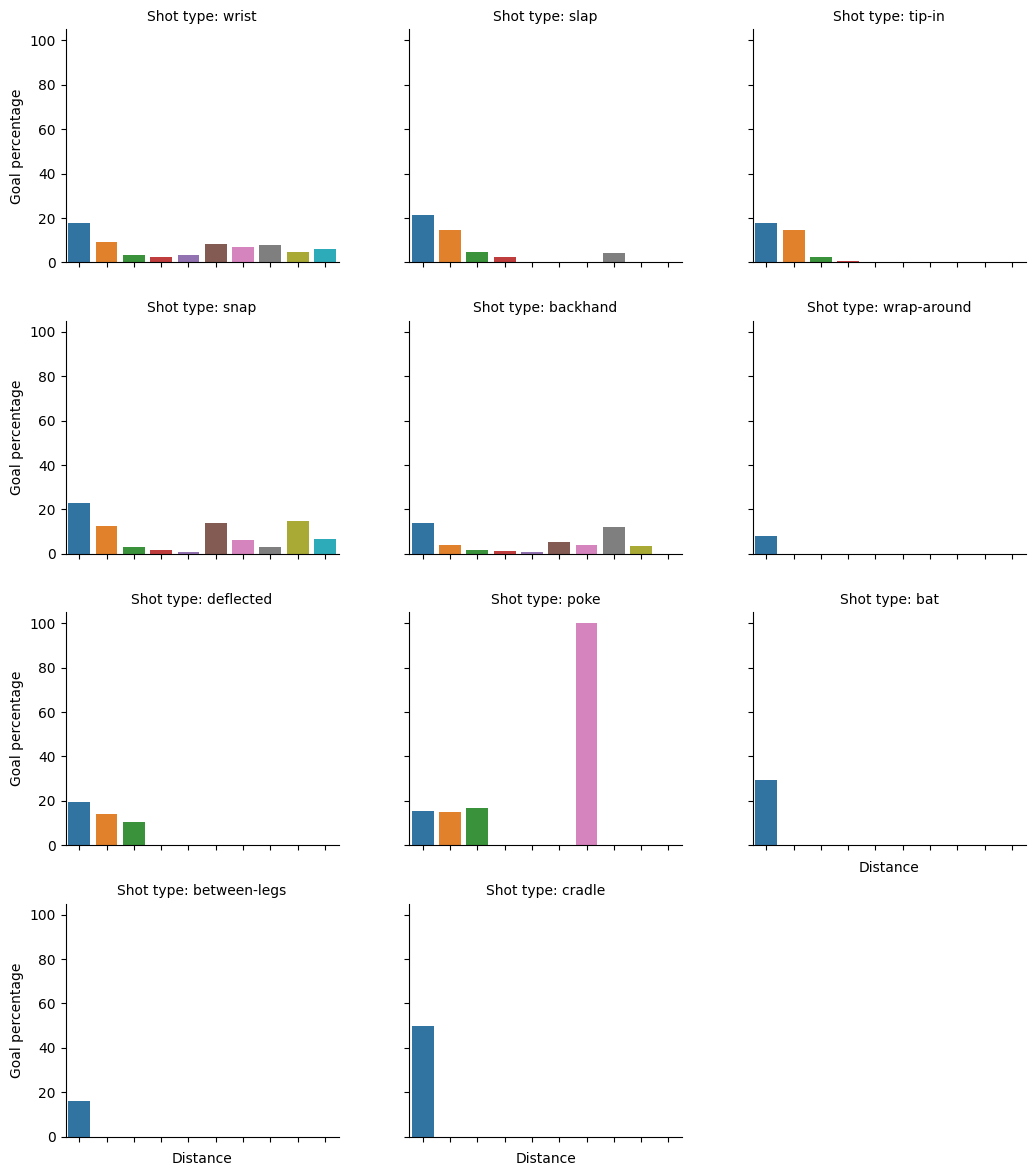

In [37]:
fig = sns.catplot(
    data = df,
    x = "bins",
    y = "percentage",
    col = "shot_type",
    kind="bar",
    col_wrap=3,
    height=3,
    aspect=1.2
)

fig.set_axis_labels("Distance", "Goal percentage")
fig.set_titles("Shot type: {col_name}")
fig.set_xticklabels(rotation=45)

plt.savefig("goal_percentage_by_distance_shot_typ.svg")
plt.show()

The most dangerous types of shots are the wrist, the snap and the poke.

The types of shot that perform the best across small to long distance are the wrist and the snap.

The type of shot with the highest goal percentage is the poke, from a distance between 120 and 140.

The following shot types can only score from a short distance : tip-in, wrap-around, deflected, bat, between-legs and cradle.